# Tutorial：Spatial multi-omics profiles generation using adult mouse cerebral cortex SNARE-seq data with mouse brain SeekSpace data as a spatial reference

## Outline

1. Import packages
2. Load data
3. Batch effect correction
4. Obtain microenvironment representations for ST data
5. Obtain microenvironment representations for scRNA-seq data
6. Optimal matching
7. Visualization of generated spatial multi-omics data
8. Spatial clustering using SpatialGlue

## 1. Import packages

We need to specify the working directory in R.

In [1]:
import scanpy as sc
import os
from pathlib import Path
import cellback as cb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
os.environ['R_HOME'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/'
os.environ['R_USER'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/library'

## 2. Load data

We integrate the RNA modality of SNARE-seq data with the spatial transcriptomics profiles from SeekSpace.

In [2]:
#Multi-omics integration
#read data (SNARE-seq RNA+ATAC; SeekSpace RNA)
data_dir = Path("../CellBack/data/multi-omics/")
slide = sc.read_h5ad(data_dir / "SeekSpace_slide.h5ad")
singlecell_RNA = sc.read_h5ad(data_dir / "SNARE-seq_RNA.h5ad")
singlecell_ATAC = sc.read_h5ad(data_dir / "SNARE-seq_ATAC.h5ad")
slide.var_names_make_unique()
singlecell_RNA.var_names_make_unique()

sc.pp.filter_cells(singlecell_RNA, min_genes=200)
sc.pp.filter_genes(singlecell_RNA, min_cells=3)

sc.pp.filter_cells(slide, min_genes=200)
sc.pp.filter_genes(slide, min_cells=3)

common_gene = slide.var_names.intersection(singlecell_RNA.var_names)
slide = slide[:, common_gene]
singlecell = singlecell_RNA[:, common_gene]

sc.pp.normalize_total(singlecell, target_sum=1e4)
sc.pp.log1p(singlecell)

sc.pp.normalize_total(slide, target_sum=1e4)
sc.pp.log1p(slide)

## 3. Batch effect correction

We use scANVI method to obtain low-dimensional embeddings for the two datasets.

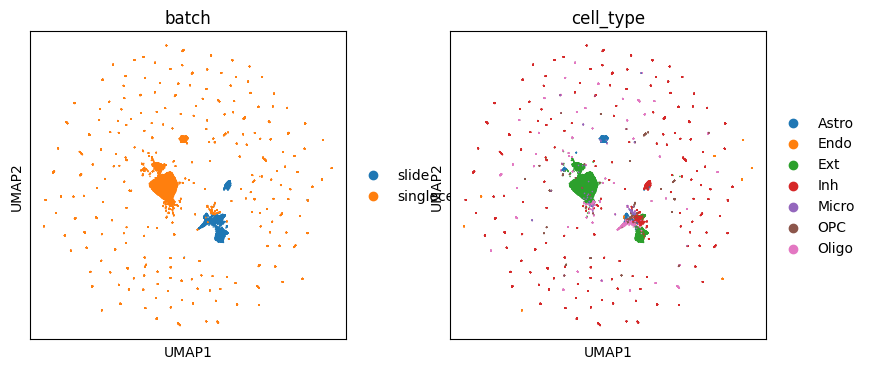

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 342/342: 100%|██████████| 342/342 [07:03<00:00,  1.22s/it, v_num=1, train_loss_step=278, train_loss_epoch=281]

`Trainer.fit` stopped: `max_epochs=342` reached.


Epoch 342/342: 100%|██████████| 342/342 [07:03<00:00,  1.24s/it, v_num=1, train_loss_step=278, train_loss_epoch=281]


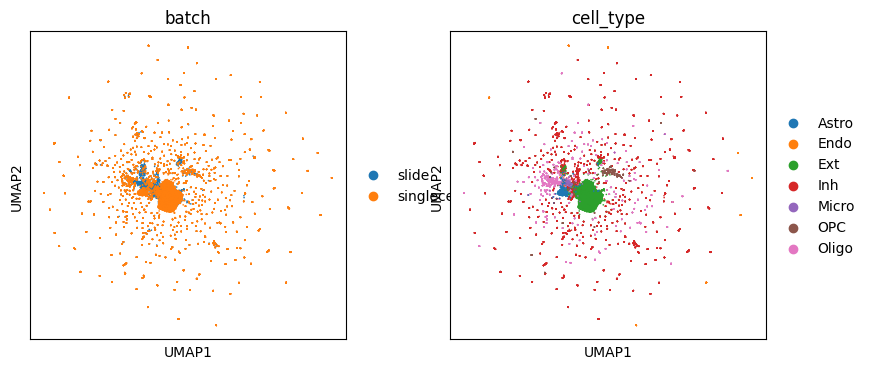

INFO     Training for 20 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 20/20: 100%|██████████| 20/20 [01:02<00:00,  3.03s/it, v_num=1, train_loss_step=259, train_loss_epoch=258]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [01:02<00:00,  3.12s/it, v_num=1, train_loss_step=259, train_loss_epoch=258]


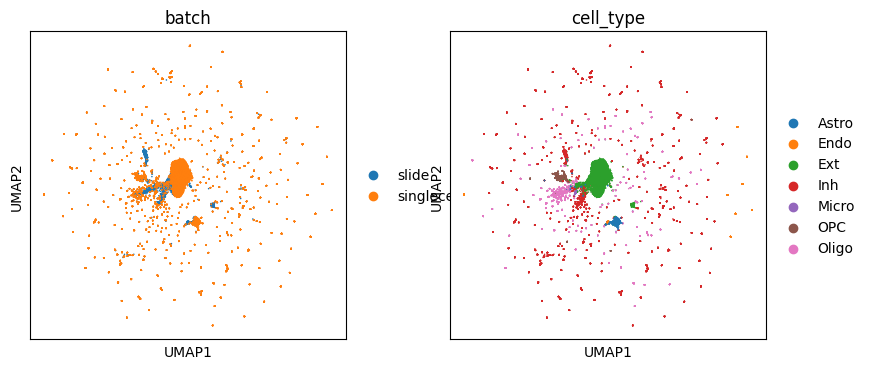

In [3]:
#We integrate two datasets using RNA modality
#remove batch effect
plt.rcParams["figure.figsize"] = (4, 4)
adata_sc, adata_sp = cb.utils.run_scvi(slide, singlecell)

We reconstruct the gene expression matrices of HVGs using Seurat to ensure that the feature dimensions are comparable.

In [4]:
#reconstruct expression matrices of HVGs
dictory_sc = "../CellBack/test/sc/"
dictory_st = "../CellBack/test/st/"
dictory_matrix = "../CellBack/test/"

adata_sc_re, adata_sp_re = cb.utils.run_seurat(adata_sp, adata_sc, dictory_sc= dictory_sc, dictory_st= dictory_st, dictory_matrix= dictory_matrix)


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    [1] 4 4 0



R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |===================================                                   |  50%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  Plp1, Mag, Mbp, Apoe, Ptgds, Cst3, Cnp, Mog, Mobp, Apod 
	   St18, Mal, Glul, Cmtm5, Atp1a2, Rnf220, Mt1, Dock10, Cldn11, Neat1 
	   Prr5l, Csrp1, Phldb1, Slc1a3, Clu, Qk, Car2, Tspan2, Ndrg2, Zbtb20 
Negative:  Meg3, Nrg3, Csmd1, Nrxn3, Dlg2, Dlgap2, Dlgap1, Opcml, Fgf14, Kcnip4 
	   Lrrtm4, Tenm2, Fam155a, Cntnap2, Erc2, Celf2, Gria3, Grin2a, Etl4, Rbfox1 
	   Kcnma1, Asic2, Lingo2, Cntn4, Mef2c, 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 23415
Number of edges: 1124654

Running Louvain algorithm...


R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

Maximum modularity in 10 random starts: 0.9416
Number of communities: 76
Elapsed time: 3 seconds


...

R[write to console]: Warning:
R[write to console]:  Layer counts isn't present in the assay object; returning NULL

R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |===================================                                   |  50%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  Cnp, Plp1, Mag, Mog, Apod, Csrp1, Tspan2, Cryab, Ptgds, Mal 
	   Ppp1r14a, Sox10, Mobp, Bcas1, Rnf220, Phldb1, Pllp, Cldn11, Dock10, Efnb3 
	   Tfeb, Cmtm5, Mbp, S100a13, Phgdh, Myrf, Padi2, Gjc2, Frmd8, Car2 
Negative:  Meg3, Celf2, Fgf14, Rbfox1, Grin2b, Dlgap2, Csmd1, Nrxn3, Dlgap1,

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 23415
Number of edges: 1239596

Running Louvain algorithm...


R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

Maximum modularity in 10 random starts: 0.9412
Number of communities: 85
Elapsed time: 4 seconds


R[write to console]: 23:05:52 UMAP embedding parameters a = 0.9922 b = 1.112

R[write to console]: 23:05:52 Read 23415 rows and found 50 numeric columns

R[write to console]: 23:05:52 Using Annoy for neighbor search, n_neighbors = 30

R[write to console]: 23:05:52 Building Annoy index with metric = cosine, n_trees = 50

R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

## 4. Obtain microenvironment representations for ST data

We use BANKSY method to obtain the microenvironment representations for the ST data. lambda_list = [0.8] indicates that the weights of intrinsic expression versus microenvironment expression are 0.2 and 0.8, respectively.

In [5]:
#run BANKSY
lambda_list = [0.8]
adata_sp_micro, micro_weight = cb.utils.run_banksy(adata_sp_re, lambda_list=lambda_list)


Median distance to closest cell = 103.81714694596457

---- Ran median_dist_to_nearest_neighbour in 0.01 s ----


Median distance to closest cell = 103.8171

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.14 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran theta_from_spatial_graph in 0.04 s ----

---- Ran row_normalize in 0.02 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.22 s ----

Runtime Jan-15-2026-23-07

2000 genes to be analysed:
Gene List:
Index(['Xkr4', 'Rp1', 'Sox17', 'St18', 'Prex2', 'Gm29570', 'Kcnb2', 'Pkhd1',
       'Kcnq5', 'Gm29506',
       ...
       'Col4a6', 'Chrdl1', 'Htr2c', '9530051G07Rik', 'Sat1', 'Ap1s2', 'Bmx',
       'Tlr7', 'Frmpd4', 'Gm21860'],
      dtype='object', length=2000)

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <4638x4638 sparse matrix of type '<class 'numpy.float64'>'
	with 69570 stored elements i

## 5. Obtain microenvironment representations for scRNA-seq data

Edges between spatial cells are controlled by parameter threshold_distance, while edges between spatial cells and single cells are based on the similarity in low-dimensional embeddings obtained from scANVI, which are stored in .obsm['X_scANVI'], with k representing the number of most similar single cells connected to each spatial cell. Then, we obtain the microenvironment representations for scRNA-seq data through a multi-head graph attention network to adaptively propagate microenvironmental information from ST data.

In [6]:
#model training
#construct graphs
edge_index_intra = cb.utils.intra_spatial_proximity(adata_sp_re,
                                                          threshold_distance=320)
edge_index_inter = cb.utils.inter_correlation_calculation(adata_sc_re,
                                                                adata_sp_re, basis='X_scANVI', k=3)
edge_index = edge_index_intra + edge_index_inter

lam = micro_weight
features, targets = cb.utils.extra_features(adata_sc_re,
                                            adata_sp_re,
                                            adata_sp_micro, lam=lam)

#microenvironment representations learning
celltype_list = adata_sc_re.obs['cell_type'].unique()
cb.micro_network_training(adata_sc=adata_sc_re,
                          adata_sp=adata_sp_re,
                          edge_index=edge_index,
                          features=features,
                          targets=targets,
                          cell_types=celltype_list,
                          epoch=30000)

100%|██████████| 4638/4638 [01:04<00:00, 71.57it/s]


Mean degree(neighbors): 3.8178094006037084


100%|██████████| 18777/18777 [1:23:32<00:00,  3.75it/s]


Epoch 0, Loss: 3.9608
Epoch 1000, Loss: 1.3606
Epoch 2000, Loss: 1.0132
Epoch 3000, Loss: 0.9284
Epoch 4000, Loss: 0.8414
Epoch 5000, Loss: 0.7861
Epoch 6000, Loss: 0.7538
Epoch 7000, Loss: 0.7302
Epoch 8000, Loss: 0.8565
Epoch 9000, Loss: 0.7172
Epoch 10000, Loss: 0.7405
Epoch 11000, Loss: 0.7019
Epoch 12000, Loss: 0.6800
Epoch 13000, Loss: 0.6689
Epoch 14000, Loss: 0.6620
Epoch 15000, Loss: 0.7448
Epoch 16000, Loss: 0.6771
Epoch 17000, Loss: 0.6810
Epoch 18000, Loss: 0.6592
Epoch 19000, Loss: 0.6508
Epoch 20000, Loss: 0.7447
Epoch 21000, Loss: 0.6480
Epoch 22000, Loss: 0.6965
Epoch 23000, Loss: 0.6516
Epoch 24000, Loss: 0.6750
Epoch 25000, Loss: 0.6459
Epoch 26000, Loss: 0.6329
Epoch 27000, Loss: 0.6235
Epoch 28000, Loss: 0.6280
Epoch 29000, Loss: 0.7155


## 6. Optimal matching

We first perform cell-type proportion–guided optimal matching based on intrinsic and microenvironment gene expression similarity to obtain correspondences between the two datasets. Subsequently, we generate pseudo-spatial coordinates for single cells using one of two modes ('perturbation' or 'repetition'), which are stored in adata_sc.obsm['pseudo_space']. As this dataset exhibit an obvious spatially symmetric structure, we set mode = 'perturbation'. The parameter scale represents the degree of random perturbation.

In [7]:
#optimal matching
adata_sc = cb.optimal_matching.matching(adata_sp_re,
                              adata_sc_re,
                              mode='perturbation', scale=300)

 Use 'perturbation' mode. 


100%|██████████| 18777/18777 [1:30:50<00:00,  3.44it/s]


## 7. Visualization of generated spatial multi-omics data

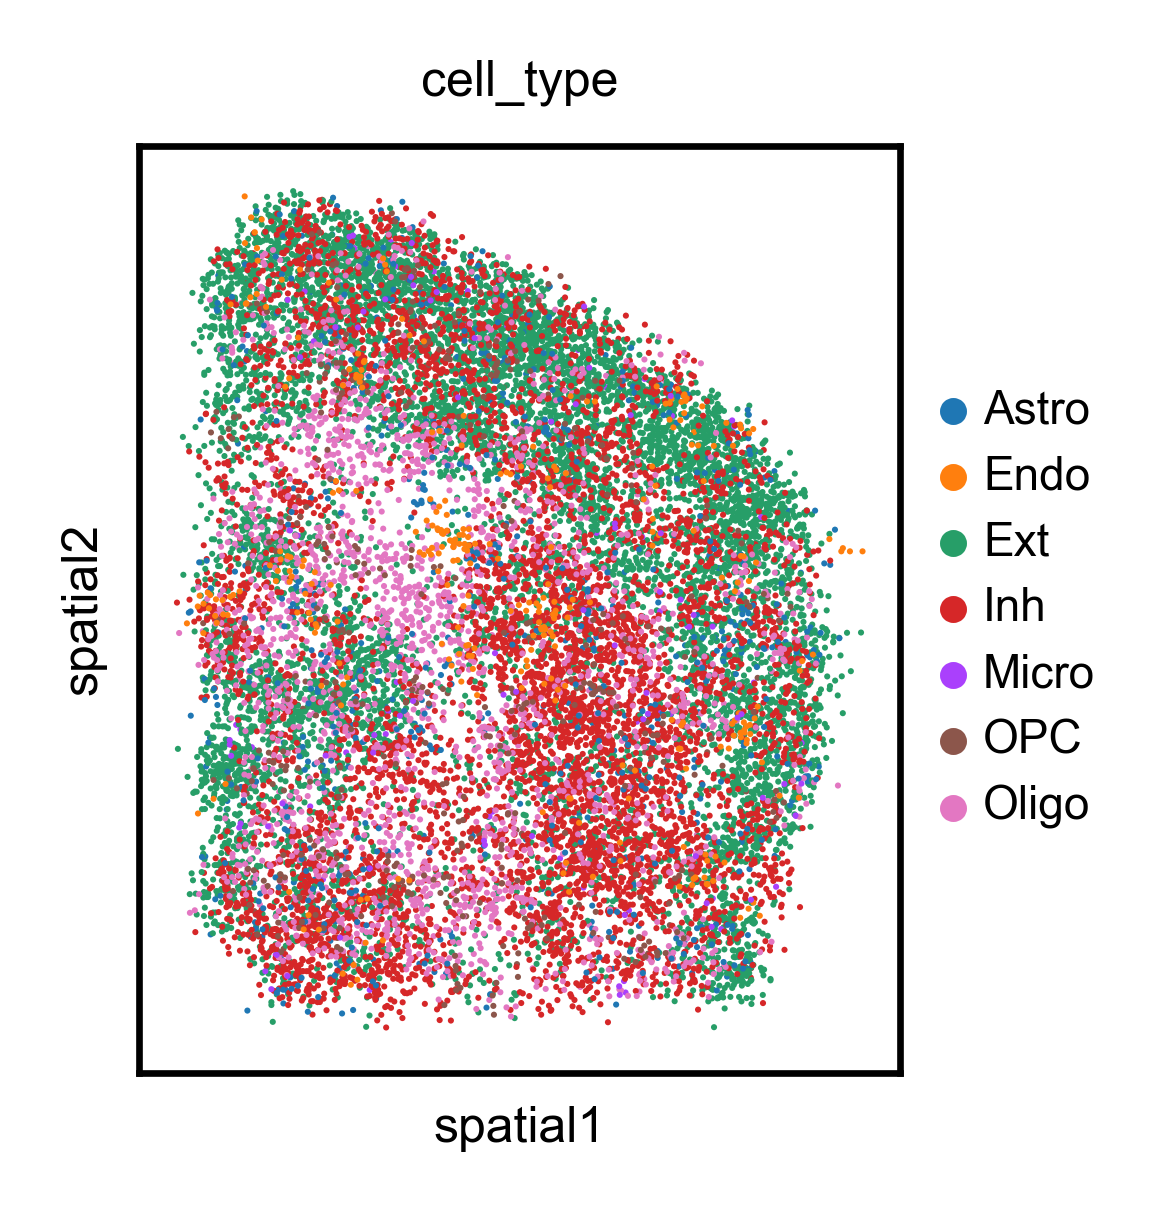

In [22]:
#spatial multi-omics profiles generation
adata_rna = sc.read_h5ad(data_dir / "SNARE-seq_RNA.h5ad")
adata_atac = sc.read_h5ad(data_dir / "SNARE-seq_RNA.h5ad")

adata_rna.obsm['spatial'] = adata_sc.obsm['pseudo_space']
adata_atac.obsm['spatial'] = adata_sc.obsm['pseudo_space']

import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.5
sc.set_figure_params(figsize=(2.5, 2), dpi=300, fontsize=6)
fig = sc.pl.spatial(adata_rna, basis="spatial", color='cell_type', show=False, return_fig=True, spot_size=150)
ax = fig.axes[0]
leg = ax.get_legend()
for h in leg.legend_handles:
    h.set_sizes([5])
fig.tight_layout()
fig.show()

## 8. Spatial clustering using SpatialGlue

For the Ext cells in this dataset, we use SpatialGlue to identify spatial domains, revealing the cortical laminar structures in the adult mouse cerebral cortex.

In [23]:
#spatial clustering using SpatialGlue
from SpatialGlue.preprocess import fix_seed
from SpatialGlue.preprocess import clr_normalize_each_cell, pca, lsi
from SpatialGlue.preprocess import construct_neighbor_graph
from SpatialGlue.SpatialGlue_pyG import Train_SpatialGlue
from SpatialGlue.utils import clustering
from scipy import sparse
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_type = 'Spatial-epigenome-transcriptome'
random_seed = 2022
fix_seed(random_seed)

#subset Ext cells
adata_atac = adata_atac[adata_atac.obs['cell_type'] == 'Ext'].copy()
adata_rna = adata_rna[adata_rna.obs['cell_type'] == 'Ext'].copy()

#preprocessing
if not sparse.isspmatrix_csr(adata_atac.X):
    adata_atac.X = sparse.csr_matrix(adata_atac.X)

peak_counts = np.array((adata_atac.X > 0).sum(axis=0)).flatten()
keep_peaks = peak_counts >= 5
adata_atac = adata_atac[:, keep_peaks]

adata_rna.var_names_make_unique()
adata_atac.var_names_make_unique()

sc.pp.filter_genes(adata_rna, min_cells=10)
sc.pp.filter_cells(adata_rna, min_genes=200)

sc.pp.normalize_total(adata_rna, target_sum=1e4)
sc.pp.log1p(adata_rna)
sc.pp.highly_variable_genes(adata_rna, flavor="seurat_v3", n_top_genes=2000)
sc.pp.scale(adata_rna)

adata_rna_high =  adata_rna[:, adata_rna.var['highly_variable']]
adata_rna.obsm['feat'] = pca(adata_rna_high, n_comps=30)

adata_atac = adata_atac[adata_rna.obs_names].copy()
if 'X_lsi' not in adata_atac.obsm.keys():
    sc.pp.highly_variable_genes(adata_atac, flavor="seurat_v3", n_top_genes=2000)
    lsi(adata_atac, use_highly_variable=False, n_components=31)

adata_atac.obsm['feat'] = adata_atac.obsm['X_lsi'].copy()

data = construct_neighbor_graph(adata_rna, adata_atac, datatype=data_type)

#cell embeddings learning via SpatialGlue
model = Train_SpatialGlue(data, datatype=data_type, device=device)
output = model.train()

adata = adata_rna.copy()
adata.obsm['emb_latent_omics1'] = output['emb_latent_omics1']
adata.obsm['emb_latent_omics2'] = output['emb_latent_omics2']
adata.obsm['SpatialGlue'] = output['SpatialGlue']
adata.obsm['alpha'] = output['alpha']
adata.obsm['alpha_omics1'] = output['alpha_omics1']
adata.obsm['alpha_omics2'] = output['alpha_omics2']

100%|██████████| 1600/1600 [00:32<00:00, 48.65it/s]


Model training finished!



We perform clustering on the low-dimensional embeddings learned by SpatialGlue setting tool='mclust'.

fitting ...
  |======================================================================| 100%


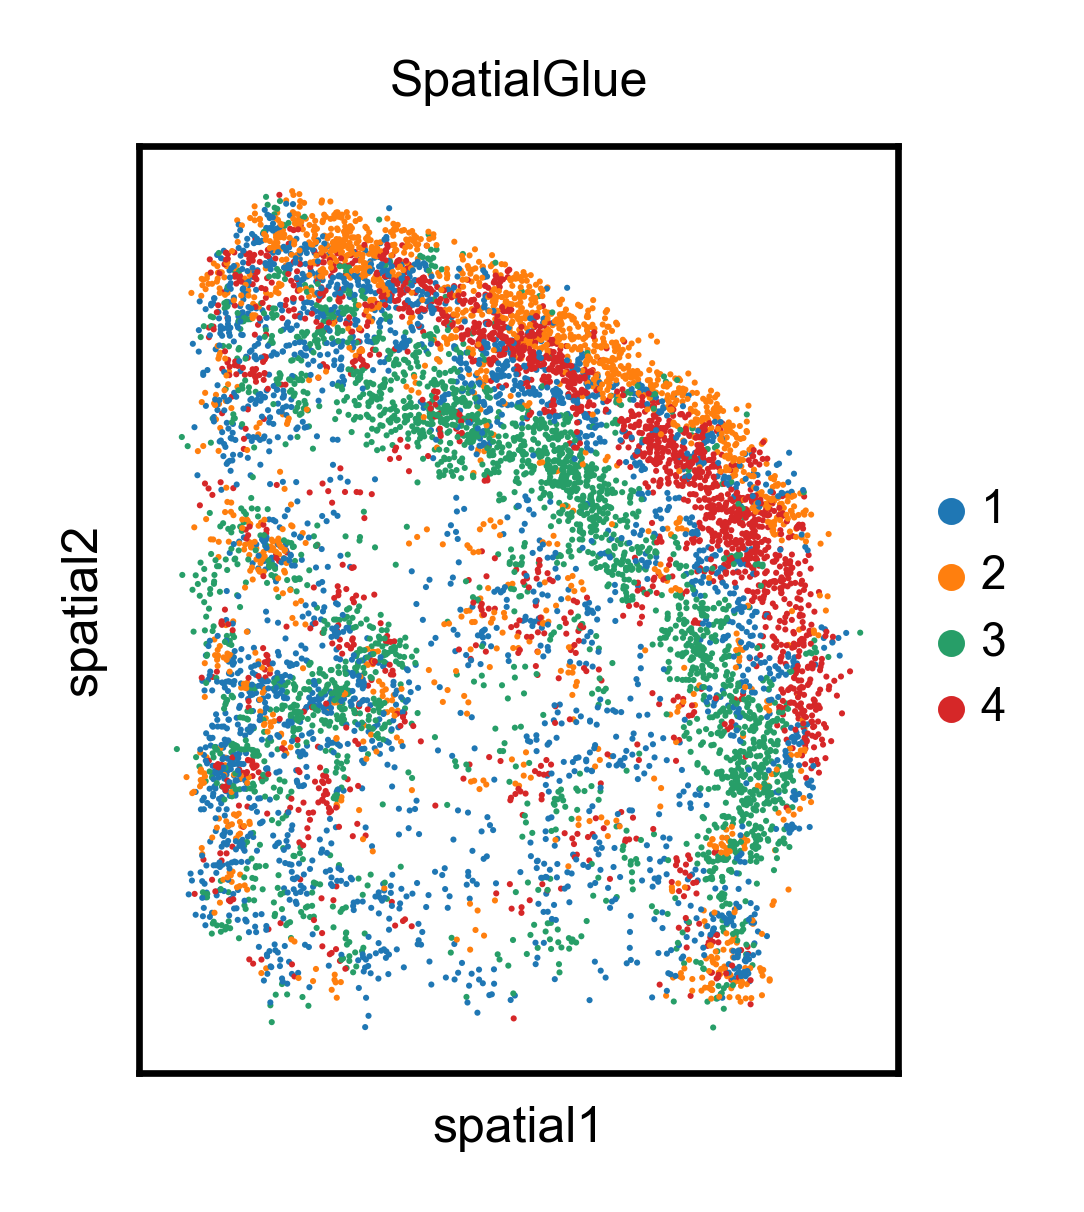

In [25]:
#clustering via mclust
tool='mclust'
clustering(adata, key='SpatialGlue', add_key='SpatialGlue', n_clusters=4, method=tool, use_pca=True)

#spatial domains visualization
import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.5
sc.set_figure_params(figsize=(2.5, 2), dpi=300, fontsize=6)
fig = sc.pl.spatial(adata, basis='spatial', color='SpatialGlue', title='SpatialGlue', spot_size=150, return_fig=True, show=False)
ax = fig.axes[0]
leg = ax.get_legend()
for h in leg.legend_handles:
    h.set_sizes([5])
fig.tight_layout()
fig.show()